# Get h5ad of *Apis mellifera*

In [ ]:
%%bash

wget -O "./matrix/GSE184507.tar" "https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE184507"

In [1]:
import scanpy as sc
import anndata as ad
from pathlib import Path

In [ ]:
# merge the 2022 Apis mellifera dataset from GEO (GSE184507_RAW.tar) into a single h5ad file
raw_dir = Path("./matrix/GSE184507_RAW")
prefixes = sorted(p.name[: -len("matrix.mtx.gz")] for p in raw_dir.glob("*matrix.mtx.gz"))

adatas = [
    sc.read_10x_mtx(raw_dir, prefix=p, var_names="gene_symbols", gex_only=True)
    for p in prefixes
]

adata = ad.concat(
    adatas,
    join="outer",
    label="sample",
    keys=[p[:-1] for p in prefixes],
    index_unique="-",
)
adata.write_h5ad("./matrix/GSE184507.h5ad")
adata

In [2]:
adata = sc.read_h5ad("./matrix/GSE184507.h5ad")
adata.obs
# 141,510 rows

,sample
AAACCCAAGAGCCTGA-1-GSM5590453_scFoager1,GSM5590453_scFoager1
AAACCCAAGAGTCACG-1-GSM5590453_scFoager1,GSM5590453_scFoager1
AAACCCAAGCACTCGC-1-GSM5590453_scFoager1,GSM5590453_scFoager1
AAACCCAAGCGCACAA-1-GSM5590453_scFoager1,GSM5590453_scFoager1
AAACCCAAGCGTCGAA-1-GSM5590453_scFoager1,GSM5590453_scFoager1
...,...
TTTGTTGTCGGCTTGG-1-GSM5590458_scQueen2,GSM5590458_scQueen2
TTTGTTGTCTACCCAC-1-GSM5590458_scQueen2,GSM5590458_scQueen2
TTTGTTGTCTCACTCG-1-GSM5590458_scQueen2,GSM5590458_scQueen2
TTTGTTGTCTCCTGAC-1-GSM5590458_scQueen2,GSM5590458_scQueen2


In [ ]:
%%bash
# adata does not contain annotations; these were obtained subsequently by contacting the original authors of iScience (2022).
ln -sf "/home/liuzhiyu/Projects/neo_caste/anno_cells/Zhang_iScience_2022_Amel/metadata/metadata.csv" "./metadata/metadata.csv"

In [3]:
import pandas as pd

Amel_anno = pd.read_csv("./metadata/metadata.csv")
Amel_anno # 115169 rows

/tmp/ipykernel_116340/649958447.py:3: DtypeWarning: Columns (5,7) have mixed types. Specify dtype option on import or set low_memory=False.
  Amel_anno = pd.read_csv("./metadata/metadata.csv")


,Unnamed: 0,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,f,n,q,integrated_snn_res.1,seurat_clusters,type,cell_type
0,F1_sc_AAACCCAAGAGCCTGA-1,F1,4938,2284,5.548805,F,NaN,NaN,24,24,F,UNs
1,F1_sc_AAACCCAAGAGTCACG-1,F1,2181,1277,7.473636,F,NaN,NaN,9,9,F,KCs
2,F1_sc_AAACCCAAGCACTCGC-1,F1,5417,2227,12.017722,F,NaN,NaN,6,6,F,OPNs
3,F1_sc_AAACCCAAGCGCACAA-1,F1,5231,2255,6.652648,F,NaN,NaN,25,25,F,Glial cells
4,F1_sc_AAACCCAAGGCCCGTT-1,F1,6388,2624,5.541641,F,NaN,NaN,34,34,F,KCs
...,...,...,...,...,...,...,...,...,...,...,...,...
115164,Q2_sc_TTTGTTGTCCGTGGCA-1,Q2,6349,2577,5.937943,NaN,NaN,Q,3,3,Q,UNs
115165,Q2_sc_TTTGTTGTCGGCTTGG-1,Q2,3377,1682,6.692330,NaN,NaN,Q,5,5,Q,KCs
115166,Q2_sc_TTTGTTGTCTACCCAC-1,Q2,1849,999,13.142239,NaN,NaN,Q,32,32,Q,Glial cells
115167,Q2_sc_TTTGTTGTCTCACTCG-1,Q2,5251,2194,4.532470,NaN,NaN,Q,11,11,Q,KCs


In [4]:
Amel_anno['Unnamed: 0'].unique()

array(['F1_sc_AAACCCAAGAGCCTGA-1', 'F1_sc_AAACCCAAGAGTCACG-1',
       'F1_sc_AAACCCAAGCACTCGC-1', ..., 'Q2_sc_TTTGTTGTCTACCCAC-1',
       'Q2_sc_TTTGTTGTCTCACTCG-1', 'Q2_sc_TTTGTTGTCTCTGGTC-1'],
      shape=(115169,), dtype=object)

In [5]:
# combine the annotations with the adata object
adata.obs.index

Index(['AAACCCAAGAGCCTGA-1-GSM5590453_scFoager1',
       'AAACCCAAGAGTCACG-1-GSM5590453_scFoager1',
       'AAACCCAAGCACTCGC-1-GSM5590453_scFoager1',
       'AAACCCAAGCGCACAA-1-GSM5590453_scFoager1',
       'AAACCCAAGCGTCGAA-1-GSM5590453_scFoager1',
       'AAACCCAAGGCCCGTT-1-GSM5590453_scFoager1',
       'AAACCCAAGGTCCGAA-1-GSM5590453_scFoager1',
       'AAACCCAAGTCTACCA-1-GSM5590453_scFoager1',
       'AAACCCAAGTTTGAGA-1-GSM5590453_scFoager1',
       'AAACCCACAAGAATGT-1-GSM5590453_scFoager1',
       ...
       'TTTGTTGGTTCAAGTC-1-GSM5590458_scQueen2',
       'TTTGTTGGTTGTTTGG-1-GSM5590458_scQueen2',
       'TTTGTTGTCCAGGACC-1-GSM5590458_scQueen2',
       'TTTGTTGTCCATGCAA-1-GSM5590458_scQueen2',
       'TTTGTTGTCCGTGGCA-1-GSM5590458_scQueen2',
       'TTTGTTGTCGGCTTGG-1-GSM5590458_scQueen2',
       'TTTGTTGTCTACCCAC-1-GSM5590458_scQueen2',
       'TTTGTTGTCTCACTCG-1-GSM5590458_scQueen2',
       'TTTGTTGTCTCCTGAC-1-GSM5590458_scQueen2',
       'TTTGTTGTCTCTGGTC-1-GSM5590458_scQueen2']

In [6]:
sample_map = {
    "GSM5590453_scFoager1": "F1", "GSM5590454_scFoager2": "F2",
    "GSM5590455_scNurse1":  "N1", "GSM5590456_scNurse2":  "N2",
    "GSM5590457_scQueen1":  "Q1", "GSM5590458_scQueen2":  "Q2",
}

barcode = adata.obs_names.str.rsplit("-", n=1).str[0] # AAACCCAAGAGCCTGA-1
code = adata.obs["sample"].astype(str).map(sample_map) # GSM...scFoager1 -> F1
adata.obs["amel_key"] = code + "_sc_" + barcode # F1_sc_AAACCCAAGAGCCTGA-1

adata.obs = adata.obs.join(Amel_anno.set_index("Unnamed: 0"), on="amel_key")

In [7]:
adata.obs

,sample,amel_key,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,f,n,q,integrated_snn_res.1,seurat_clusters,type,cell_type
AAACCCAAGAGCCTGA-1-GSM5590453_scFoager1,GSM5590453_scFoager1,F1_sc_AAACCCAAGAGCCTGA-1,F1,4938.0,2284.0,5.548805,F,NaN,NaN,24.0,24.0,F,UNs
AAACCCAAGAGTCACG-1-GSM5590453_scFoager1,GSM5590453_scFoager1,F1_sc_AAACCCAAGAGTCACG-1,F1,2181.0,1277.0,7.473636,F,NaN,NaN,9.0,9.0,F,KCs
AAACCCAAGCACTCGC-1-GSM5590453_scFoager1,GSM5590453_scFoager1,F1_sc_AAACCCAAGCACTCGC-1,F1,5417.0,2227.0,12.017722,F,NaN,NaN,6.0,6.0,F,OPNs
AAACCCAAGCGCACAA-1-GSM5590453_scFoager1,GSM5590453_scFoager1,F1_sc_AAACCCAAGCGCACAA-1,F1,5231.0,2255.0,6.652648,F,NaN,NaN,25.0,25.0,F,Glial cells
AAACCCAAGCGTCGAA-1-GSM5590453_scFoager1,GSM5590453_scFoager1,F1_sc_AAACCCAAGCGTCGAA-1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGTTGTCGGCTTGG-1-GSM5590458_scQueen2,GSM5590458_scQueen2,Q2_sc_TTTGTTGTCGGCTTGG-1,Q2,3377.0,1682.0,6.692330,NaN,NaN,Q,5.0,5.0,Q,KCs
TTTGTTGTCTACCCAC-1-GSM5590458_scQueen2,GSM5590458_scQueen2,Q2_sc_TTTGTTGTCTACCCAC-1,Q2,1849.0,999.0,13.142239,NaN,NaN,Q,32.0,32.0,Q,Glial cells
TTTGTTGTCTCACTCG-1-GSM5590458_scQueen2,GSM5590458_scQueen2,Q2_sc_TTTGTTGTCTCACTCG-1,Q2,5251.0,2194.0,4.532470,NaN,NaN,Q,11.0,11.0,Q,KCs
TTTGTTGTCTCCTGAC-1-GSM5590458_scQueen2,GSM5590458_scQueen2,Q2_sc_TTTGTTGTCTCCTGAC-1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
adata = adata[~adata.obs["orig.ident"].isna()].copy()
adata.obs
# After removing NAs, 115,169 rows in total, matching Amel_anno;

,sample,amel_key,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,f,n,q,integrated_snn_res.1,seurat_clusters,type,cell_type
AAACCCAAGAGCCTGA-1-GSM5590453_scFoager1,GSM5590453_scFoager1,F1_sc_AAACCCAAGAGCCTGA-1,F1,4938.0,2284.0,5.548805,F,NaN,NaN,24.0,24.0,F,UNs
AAACCCAAGAGTCACG-1-GSM5590453_scFoager1,GSM5590453_scFoager1,F1_sc_AAACCCAAGAGTCACG-1,F1,2181.0,1277.0,7.473636,F,NaN,NaN,9.0,9.0,F,KCs
AAACCCAAGCACTCGC-1-GSM5590453_scFoager1,GSM5590453_scFoager1,F1_sc_AAACCCAAGCACTCGC-1,F1,5417.0,2227.0,12.017722,F,NaN,NaN,6.0,6.0,F,OPNs
AAACCCAAGCGCACAA-1-GSM5590453_scFoager1,GSM5590453_scFoager1,F1_sc_AAACCCAAGCGCACAA-1,F1,5231.0,2255.0,6.652648,F,NaN,NaN,25.0,25.0,F,Glial cells
AAACCCAAGGCCCGTT-1-GSM5590453_scFoager1,GSM5590453_scFoager1,F1_sc_AAACCCAAGGCCCGTT-1,F1,6388.0,2624.0,5.541641,F,NaN,NaN,34.0,34.0,F,KCs
...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGTTGTCCGTGGCA-1-GSM5590458_scQueen2,GSM5590458_scQueen2,Q2_sc_TTTGTTGTCCGTGGCA-1,Q2,6349.0,2577.0,5.937943,NaN,NaN,Q,3.0,3.0,Q,UNs
TTTGTTGTCGGCTTGG-1-GSM5590458_scQueen2,GSM5590458_scQueen2,Q2_sc_TTTGTTGTCGGCTTGG-1,Q2,3377.0,1682.0,6.692330,NaN,NaN,Q,5.0,5.0,Q,KCs
TTTGTTGTCTACCCAC-1-GSM5590458_scQueen2,GSM5590458_scQueen2,Q2_sc_TTTGTTGTCTACCCAC-1,Q2,1849.0,999.0,13.142239,NaN,NaN,Q,32.0,32.0,Q,Glial cells
TTTGTTGTCTCACTCG-1-GSM5590458_scQueen2,GSM5590458_scQueen2,Q2_sc_TTTGTTGTCTCACTCG-1,Q2,5251.0,2194.0,4.532470,NaN,NaN,Q,11.0,11.0,Q,KCs


In [9]:
# In the original 2022 iScience article, the authors incorrectly labeled the mitochondrial genes; the "MT-" prefix has been removed in all instances here.
adata.var_names = adata.var_names.str.replace("^MT-", "", regex=True)
adata.var_names_make_unique()
adata.write_h5ad("./matrix/Amel_wll.h5ad")

# Get Orthologs

In [ ]:
%%bash

cp "/home/liuzhiyu/Projects/neo_caste/Find_Ortholog/primary_transcripts/OrthoFinder/Results_Sep13/Orthologues/Orthologues_Apis_cerana/Apis_cerana__v__Apis_mellifera.tsv" "./orthologs/Apis_cerana__v__Apis_mellifera.tsv"

In [10]:
import pandas as pd

Acer_vs_Amel = pd.read_csv("./orthologs/Apis_cerana__v__Apis_mellifera.tsv", sep="\t")

In [11]:
def get_121_orthologs(df, sp1, sp2):
    # 只考虑两列都不含逗号的“候选单基因”
    df = df[
        ~df[sp1].str.contains(",", na=False)
        & ~df[sp2].str.contains(",", na=False)
    ].copy()

    # 严格一对一：sp1 和 sp2 各自都不允许出现重复值
    df = df[
        ~df.duplicated(subset=[sp1], keep=False)
        & ~df.duplicated(subset=[sp2], keep=False)
    ]
    #! 注意！！如果不这样做，某列仍然可能同时存在多行相同基因（即未除尽的一对多）
    #! 并且千万不要用简单的 .drop_duplicates(sp1).drop_duplicates(sp2)，因为会保留 sp1/sp2 列第一次出现的行，正常情况下应该将一对多的行全部去掉
    return df.drop_duplicates().reset_index(drop=True)

In [12]:
Acer_vs_Amel_121 = get_121_orthologs(Acer_vs_Amel, "Apis_cerana", "Apis_mellifera")

In [13]:
Acer_vs_Amel_121.to_csv("./orthologs/Acer_vs_Amel_121.tsv", sep="\t", index=False)

# Check .h5ad gene id/gene name

OrthoFinder results are based on the `gene_id` column in the GTF file; however, since `anndata.var.index` in `h5ad` files from different sources is not necessarily the `gene_id`, this issue is addressed here.

In [ ]:
%%bash
# get GTF data
wget -O "./metadata/Apis_mellifera.gtf.gz" "https://ftp.ensemblgenomes.ebi.ac.uk/pub/metazoa/current/gtf/apis_mellifera/Apis_mellifera.Amel_HAv3.1.63.gtf.gz"
gunzip "./metadata/Apis_mellifera.gtf.gz"

In [ ]:
%%bash
gppy txinfo -g "./metadata/Apis_mellifera.gtf" > "./metadata/Apis_mellifera.tsv"
cp "/home/liuzhiyu/Projects/neo_caste/ApisSCENIC/.subprojects/03_is_my_orthofinder_wrong/gtf/Apis_cerana.tsv" "./metadata/Apis_cerana.tsv"

In [14]:
import pandas as pd

Amel_gtf = pd.read_csv("./metadata/Apis_mellifera.tsv", sep="\t")

In [15]:
import scanpy as sc

Amel = sc.read_h5ad("./matrix/Amel_wll.h5ad")

In [16]:
Amel_set = set(Amel.var.index)

In [17]:
Amel_121_set = set(Acer_vs_Amel_121["Apis_mellifera"].to_list())

In [18]:
Amel_gid_set = set(Amel_gtf["gene_id"].to_list())

目前已知，XXX_121_set 是特定物种与 *A. cerana* 一对一同源基因中，该物种基因的集合；XXX_set 是其他文章提供的表达矩阵中，该物种基因的集合；XXX_gid_set 是该物种 GTF 中，gene_id 列基因的集合。已知同源基因的计算是基于最新注释的，因此 XXX_121_set 一定是 XXX_gid_set 的子集。

但目前不确定的是 XXX_set，因为其对应的表达矩阵来自几年前的文章，不一定使用最新版的基因组注释。如果 XXX_set 不是 XXX_gid_set 的子集（或者说，XXX_set 中存在 XXX_gid_set 中没有的基因），可能会导致 XXX_121_set 与 XXX_set 的交集偏少，因此需核查 XXX_set 与 XXX_gid_set 的关系。

It is established that `XXX_121_set` represents the set of genes from a specific species involved in one-to-one orthologous pairs with *A. cerana*; `XXX_set` represents the set of genes from that species found in an expression matrix from a previous study; and `XXX_gid_set` represents the set of genes listed in the `gene_id` column of that species' GTF file. Since the orthologous gene identification was based on the latest annotation, `XXX_121_set` is necessarily a subset of `XXX_gid_set`.

However, the status of `XXX_set` is uncertain because the corresponding expression matrix originates from a study published several years ago and may not utilize the most recent genome annotation. If `XXX_set` is not a subset of `XXX_gid_set` (i.e., if `XXX_set` contains genes absent from `XXX_gid_set`), the intersection between `XXX_121_set` and `XXX_set` might be artificially low; therefore, the relationship between `XXX_set` and `XXX_gid_set` requires verification.

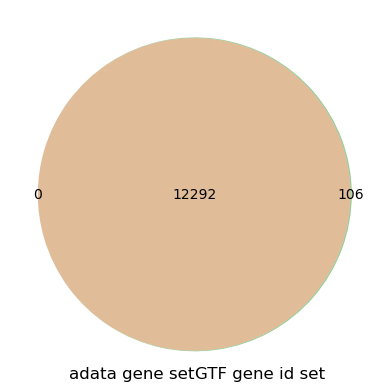

adata gene num: 12292
gtf gene num: 12398
adata ∩ gtf: 12292


In [19]:
from matplotlib_venn import venn2
import matplotlib.pyplot as plt

v = venn2([Amel_set, Amel_gid_set], set_labels=("adata gene set", "GTF gene id set"))
plt.show()

print(f"adata gene num: {len(Amel_set)}")
# print(f"ortho gene num: {len(Amel_121_set)}")
print(f"gtf gene num: {len(Amel_gid_set)}")

print(f"adata ∩ gtf: {len(Amel_set & Amel_gid_set)}")

*A. mellifera*: 0 genes of `adata gene set` not in `GTF gene id set`

↑ 蜜蜂的 adata 中基因名称全部位于 GTF gene_id 列，可以用于后续与直系同源基因取交集

# Get gene list for MetaNeighbor

Not all genes in Acer_vs_XXX_121.tsv can be used in MetaNeighbor: 

In [20]:
import scanpy as sc
import pandas as pd

In [46]:
Amel = sc.read_h5ad("./matrix/Amel_wll.h5ad")

In [22]:
Amel_set = set(Amel.var.index)

In [23]:
Acer_vs_Amel_121 = pd.read_csv("./orthologs/Acer_vs_Amel_121.tsv", sep="\t")
Amel_121_set = set(Acer_vs_Amel_121["Apis_mellifera"].to_list())

Acer_vs_XXX_121 中部分基因可能出现在了原始表达矩阵中，但在质控过程中被过滤掉，因此没有出现在 XXX_set 中，而出现在 XXX_set 中的基因，很多又与 *A. cerana* 无直系同源关系，因此没有出现在 Acer_vs_XXX_121 中

Some genes from Acer_vs_XXX_121 may have been present in the initial expression matrix but were filtered out during quality control—and thus do not appear in XXX_set—whereas many genes found in XXX_set lack direct orthologs in *A. cerana* and therefore do not appear in Acer_vs_XXX_121.

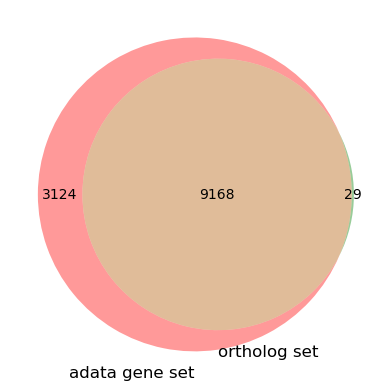

In [24]:
from matplotlib_venn import venn2
import matplotlib.pyplot as plt

v = venn2([Amel_set, Amel_121_set], set_labels=("adata gene set", "ortholog set"))
plt.show()

In [25]:
def get_121_for_mn(
        adata_gid_set: set, 
        ortho_121_set: set, 
        ortho_121_table: pd.DataFrame,
        sp_name: str
    ):
    inter = adata_gid_set & ortho_121_set
    sub_table = ortho_121_table[ortho_121_table[sp_name].isin(inter)]
    return sub_table

In [26]:
Acer_vs_Amel_121_4mn = get_121_for_mn(Amel_set, Amel_121_set, Acer_vs_Amel_121, "Apis_mellifera")

In [27]:
Acer_vs_Amel_121_4mn.to_csv("./orthologs/Acer_vs_Amel_121_4mn.tsv", sep="\t", index=False)

# Prepare .h5ad for MetaNeighbor (R) input:

The data will then be exported, after which it will be read and transformed in R for use in the MetaNeighbor pipeline.

In [40]:
Amel

AnnData object with n_obs × n_vars = 115169 × 12292
    obs: 'sample', 'amel_key', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'f', 'n', 'q', 'integrated_snn_res.1', 'seurat_clusters', 'type', 'cell_type'

(1) 保存前建议对 Amel 做的处理

必要

1. 确认 .X 是原始 counts（已满足）。
2. 确认 var_names 和 obs_names 唯一（当前已满足）。
3. 清理 cell_type 标签
- cell_type 现在是 category，建议转成字符串；
- 去掉 NaN；
- 把空格、., | 等替换成 _，例如 Glial cells → Glial_cells，避免后续 R 脚本拆分 Study_ID|Celltype 或按 . 分割时出问题。
4. 只保留需要的 obs 列
- 对 05_cross_species 来说，cell_type 就够；
- 如果还想保留样本信息，可加 sample、orig.ident；
- 建议删掉 n、q 这类含 NaN 且无用的列，减少 R 转换问题。

(2) 判断 .X 是否为原始 counts

建议检查以下几条：

1. 非零值是非负整数；
2. 每行之和等于原始 library size（nCount_RNA / total_counts / n_counts）；
3. 没有负值、NaN、Inf；
4. 没有全零细胞；
5. X.shape == (n_obs, n_vars)，即细胞 × 基因；
6. 最好能和原始来源（如 10x matrix.mtx 或 nCount_RNA）对上。
其中 “行和等于原始 library size” 是最强的证据。只有“整数”还不够，因为有人可能把 normalized counts 乘 10000 后取整，但那样行和通常不会等于原始 nCount_RNA。

In [47]:
# 检查anndata
import numpy as np
import scipy.sparse as sp

X = Amel.X
if not sp.issparse(X):
    X = sp.csr_matrix(X)
else:
    X = X.tocsr()

d = X.data
row_sums = np.asarray(X.sum(axis=1)).ravel()
col_sums = np.asarray(X.sum(axis=0)).ravel()

print("shape:", X.shape)
print("dtype:", X.dtype)
print("min / max:", d.min(), d.max())
print("all finite:", np.isfinite(d).all())
print("nonnegative:", (d >= 0).all())
print("integer-valued:", np.allclose(d, np.round(d)))
print("zero cells:", (row_sums == 0).sum())
print("zero genes:", (col_sums == 0).sum())

if "nCount_RNA" in Amel.obs:
    obs_total = Amel.obs["nCount_RNA"].values.astype(float)
    diff = np.abs(row_sums - obs_total)
    print("max |row_sum - nCount_RNA|:", diff.max())
    print("allclose:", np.allclose(row_sums, obs_total))

print("var_names unique:", Amel.var_names.is_unique)
print("obs_names unique:", Amel.obs_names.is_unique)

shape: (115169, 12292)
dtype: float32
min / max: 1.0 6316.0
all finite: True
nonnegative: True
integer-valued: True
zero cells: 0
zero genes: 545
max |row_sum - nCount_RNA|: 0.0
allclose: True
var_names unique: True
obs_names unique: True


In [48]:
# 保存前清理代码
# 删除全零基因，仅保留 Amel & Acer一对一直系同源基因
Acer_Amel_121_set = set(Acer_vs_Amel_121_4mn["Apis_mellifera"].to_list())
expressed = np.asarray(Amel.X.sum(axis=0)).ravel() > 0
in_ortholog = Amel.var_names.isin(Acer_Amel_121_set)
gene_keep = expressed & in_ortholog
Amel = Amel[:, gene_keep].copy()

# 清理细胞类型标签
Amel.obs["cell_type"] = (
    Amel.obs["cell_type"]
    .astype(str)
    .str.replace(r"[.\|\s]+", "_", regex=True)
)

# 只保留需要的 obs 列
Amel.obs = Amel.obs[["cell_type", "sample", "orig.ident"]].copy()
Amel.obs["cell_type"] = Amel.obs["cell_type"].astype("category")
Amel.obs["cell_type"] = Amel.obs["cell_type"].cat.remove_unused_categories()

# 再精简
Amel.layers = {}
Amel.obsm = {}
Amel.varm = {}
Amel.obsp = {}
Amel.uns = {}
Amel.raw = None

assert Amel.var_names.is_unique
assert Amel.obs_names.is_unique
assert Amel.obs["cell_type"].notna().all()

Amel

AnnData object with n_obs × n_vars = 115169 × 9154
    obs: 'cell_type', 'sample', 'orig.ident'

In [51]:
Amel.write_h5ad("./matrix/Amel_wll_4_MetaNeighboR.h5ad")